In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from autorank import autorank, plot_stats, create_report
from itertools import permutations
from scipy.stats import wilcoxon

from deepfake.constants import WAVELET_FAMILIES
from deepfake.data import frequency_ordered_nodes

In [26]:
df = pd.read_csv("./results/train_all/results.csv")
df.head()

,seed,pooling,wavelet,node,eval_split,eer,roc_auc,best_epoch,best_dev_eer,train_time_s
0,42,wavelet,db4,aaa,ASVspoof 2019,0.089055,0.968398,7,0.070244,1560.8
1,42,wavelet,db4,aad,ASVspoof 2019,0.059957,0.983775,10,0.047891,1957.2
2,42,wavelet,db4,add,ASVspoof 2019,0.075194,0.976639,26,0.048665,3739.5
3,42,wavelet,db4,ada,ASVspoof 2019,0.074755,0.976887,10,0.059323,1899.2
4,42,wavelet,db4,dda,ASVspoof 2019,0.100341,0.962619,18,0.086340,2872.3


In [27]:
df_2019 = df[df["eval_split"] == "ASVspoof 2019"]
df_2021 = df[df["eval_split"] == "ASVspoof 2021"]

In [ ]:
nodes = frequency_ordered_nodes(level=3)
wavelets = WAVELET_FAMILIES

columns = [
    f"{wavelet}_{node}"
    for wavelet in wavelets
    for node in nodes
] + ["average", "max"]

## ASVspoof 2019

In [37]:
df_2019["configuration"] = np.where(
    df_2019["pooling"] == "wavelet",
    df_2019["wavelet"] + "_" + df_2019["node"],
    df_2019["pooling"]
)

autorank_input_2019 = df_2019.pivot_table(
    index="seed",
    columns="configuration",
    values="eer",
    aggfunc="mean"
)

autorank_input_2019 = autorank_input_2019[columns]

autorank_input_2019

configuration,db4_aaa,db4_aad,db4_ada,db4_add,db4_daa,db4_dad,db4_dda,db4_ddd,db8_aaa,db8_aad,...,db38_aaa,db38_aad,db38_ada,db38_add,db38_daa,db38_dad,db38_dda,db38_ddd,average,max
seed,,,,,,,,,,,,,,,,,,,,,
42,0.089055,0.059957,0.074755,0.075194,0.222845,0.079522,0.100341,0.095313,0.065392,0.068106,...,0.079276,0.150265,0.118268,0.128355,0.259032,0.204641,0.120867,0.184506,0.067176,0.049217
52,0.053568,0.050170,0.083904,0.079807,0.187512,0.078023,0.099941,0.103723,0.090985,0.064715,...,0.066484,0.121959,0.118806,0.160989,0.233992,0.168308,0.118422,0.197283,0.067737,0.052892


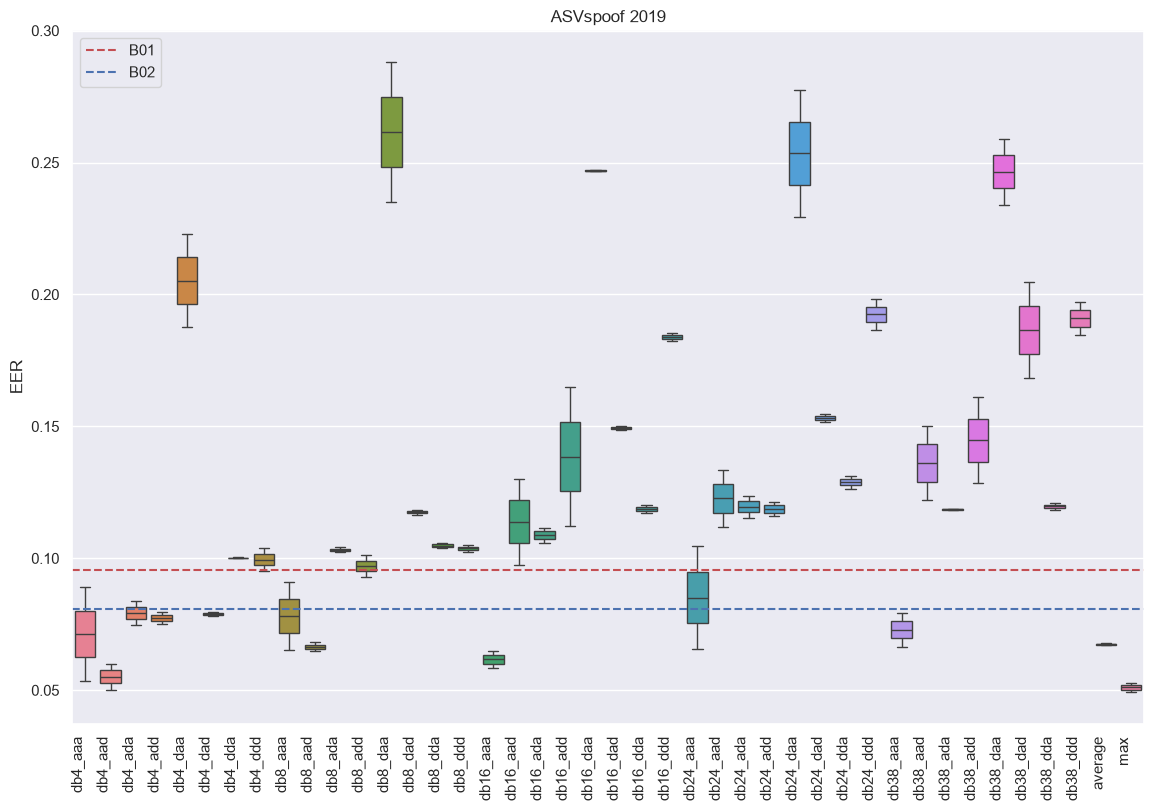

In [38]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.boxplot(data=autorank_input_2019)
plt.title("ASVspoof 2019")

baseline_b01 = 0.0957
baseline_b02 = 0.0809

plt.axhline(baseline_b01, color='r', linestyle='--', label='B01')
plt.axhline(baseline_b02, color='b', linestyle='--', label='B02')

plt.xticks(rotation=90, ha='right')

plt.xlabel("")
plt.ylabel("EER")
plt.tight_layout()
plt.legend(loc="upper left")
plt.show()

In [41]:
result_2019 = autorank(autorank_input_2019, alpha=0.05, verbose=False, order='ascending')
print(result_2019)

ValueError: requires at least five performance estimations (i.e., rows)

In [ ]:
create_report(result_2019)

In [ ]:
plot_stats(result_2019, allow_insignificant=True)

In [42]:
bayesian_result_2019 = autorank(
    autorank_input_2019, 
    alpha=0.05, 
    approach='bayesian', 
    rope=0.001,
    verbose=False, 
    order='ascending'
)

ValueError: requires at least five performance estimations (i.e., rows)

In [ ]:
create_report(bayesian_result_2019)

In [ ]:
perms = list(permutations(autorank_input_2019.columns, 2))

distinct_permutations = []

for p in perms:
    if sorted(p) not in distinct_permutations:
        distinct_permutations.append(sorted(p))

for permutation in distinct_permutations:
    family_1 = autorank_input_2019[permutation[0]].to_list()
    family_2 = autorank_input_2019[permutation[1]].to_list()
    stat, pvalue = wilcoxon(family_1, family_2)

    if pvalue < 0.05:
        print(permutation)
        print(f"Stat: {stat}, p-value: {pvalue}", "H1" if pvalue < 0.05 else "H0")
        print()

Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 1.0, p-value: 1.0 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
Stat: 0.0, p-value: 0.5 H0
S

## ASVspoof 2021